In [1]:

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import detect, evaluate, generate
from src.config import (
    CALIBRATION_PATH,
    GROUND_TRUTH_POINTS_PATH,
    IMAGES_DIR,
    METRICS_PATH,
    MIN_BLOB_AREA_PX,
    PREDICTIONS_PATH,
    SATURATION_THRESHOLD,
    SUMMARY_PATH,
)

# Odczyt punktów z wykresu

Ten notebook wczytuje dane i wyniki zapisane wcześniej przez `python -m src.generate`,
`python -m src.detect` i `python -m src.evaluate` (pliki w `data/` i `results/`).
Detekcję punktów i dopasowanie do ground truth pokazuję na żywo tylko na kilku
przykładowych obrazach, żeby zilustrować, jak działają; pełne wyniki na całym zbiorze
pochodzą z zapisanych plików.

## 1. Dane

Zbiór jest syntetyczny, generuję go sam w `src/generate.py` za pomocą matplotlib
(sposób odtworzenia opisany w README). 10 obrazów trafia do dev, 20 do test, z innego
zakresu seedów niż dev, więc test nie powtarza obrazów z dev.

In [2]:
calibration_df = pd.read_csv(CALIBRATION_PATH)
calibration_indexed = calibration_df.set_index("image_id")
ground_truth_df = pd.read_csv(GROUND_TRUTH_POINTS_PATH)

calibration_df.groupby("split").agg(
    n_images=("image_id", "count"),
    n_points_min=("n_points", "min"),
    n_points_max=("n_points", "max"),
    n_colors=("color", "nunique"),
    n_with_grid=("grid", "sum"),
)

,n_images,n_points_min,n_points_max,n_colors,n_with_grid
split,,,,,
dev,10,5,15,5,5
test,20,5,14,6,13


Kilka przykładowych obrazów z dev i test: widać różne kolory markerów, liczby
punktów i siatkę włączoną albo wyłączoną.

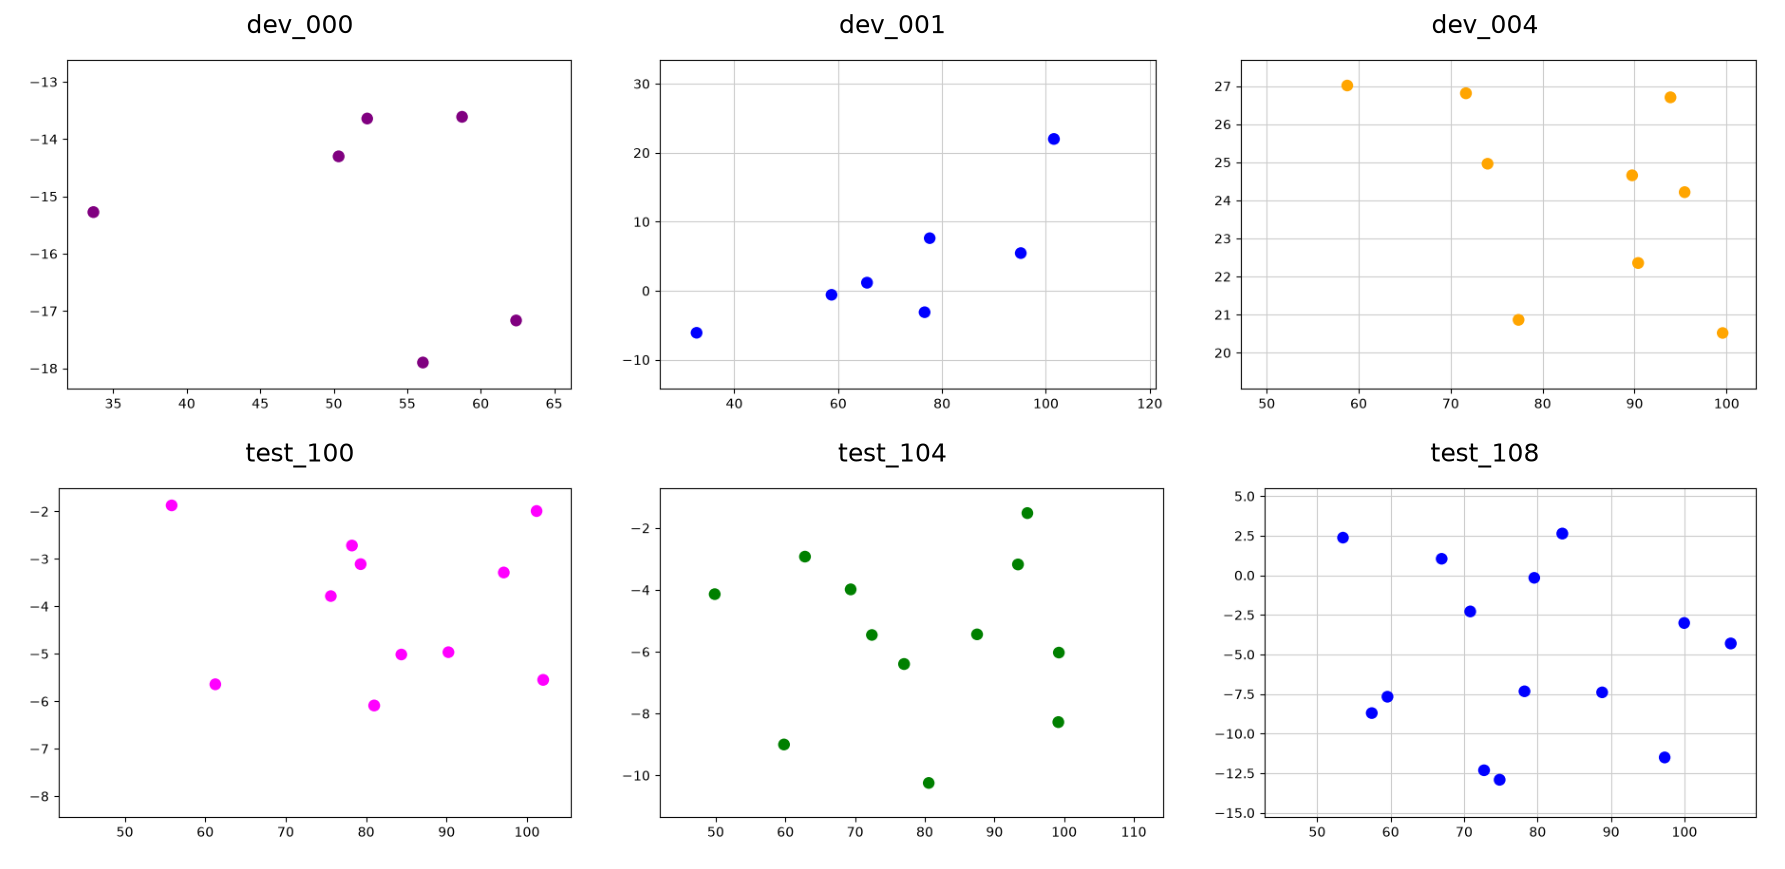

In [3]:
examples = ["dev_000", "dev_001", "dev_004", "test_100", "test_104", "test_108"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=150)
for ax, image_id in zip(axes.ravel(), examples):
    split = calibration_indexed.loc[image_id, "split"]
    image = plt.imread(IMAGES_DIR / split / f"{image_id}.png")
    ax.imshow(image)
    ax.set_title(image_id)
    ax.axis("off")
fig.tight_layout()

## 2. Kalibracja

Nie zapisuję osobnych znaczników podziałki. Przy generowaniu obrazu zapisuję krawędzie
obszaru wykresu w pikselach (`px_left`, `px_right`, `px_top`, `px_bottom`) i
odpowiadające im wartości osi (`x_min`, `x_max`, `y_min`, `y_max`). To jest odpowiednik
ręcznego podania dwóch punktów odniesienia na każdej osi, tu znany wprost z wykresu,
a nie odczytany z obrazu. Same współrzędne wykrytych punktów nadal pochodzą z analizy
obrazu w `detect.py`.

Żeby sprawdzić, czy przeliczenie piksel-wartość się zgadza, nanoszę prawdziwe punkty
(przeliczone przez kalibrację) na zapisany obraz. Powinny trafić dokładnie w środki
markerów.

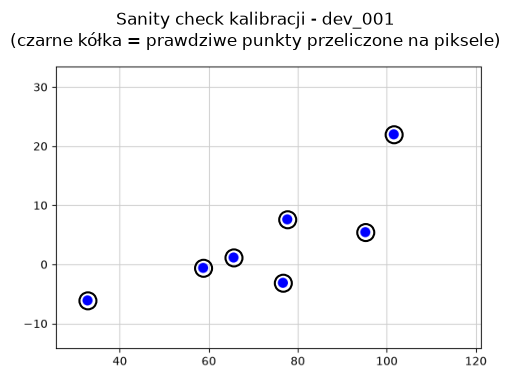

In [4]:
example_id = "dev_001"
example_calibration = calibration_indexed.loc[example_id]
example_points = ground_truth_df[ground_truth_df["image_id"] == example_id]
fig = generate.save_calibration_sanity_check(
    example_id, example_calibration["split"], example_calibration, example_points
)

## 3. Detekcja

Markery są zawsze kolorowe, a osie, siatka i tekst czarno-szare, więc do detekcji
wystarczy jeden próg nasycenia w HSV. Progi dobrałem na dev: markery mają nasycenie
dokładnie 255, tło (osie, siatka, tekst) ma nasycenie bliskie 0, więc próg nasycenia
mogłem ustawić gdziekolwiek pomiędzy. Pojedynczy marker ma powierzchnię około
100 px², więc minimalny rozmiar plamy ustawiłem znacznie niżej, żeby odcinał tylko
wyraźny szum, nie realne markery. Rzeczywiste wartości progów z `config.py`:

In [5]:
print(f"SATURATION_THRESHOLD = {SATURATION_THRESHOLD}")
print(f"MIN_BLOB_AREA_PX = {MIN_BLOB_AREA_PX}")

SATURATION_THRESHOLD = 100
MIN_BLOB_AREA_PX = 50


Piksele powyżej progu nasycenia grupuję w plamy (kontury), odrzucam te mniejsze
niż `MIN_BLOB_AREA_PX`, a środek każdej pozostałej plamy to wykryty punkt.

Poniżej maska progowania i wykryte środki na jednym przykładzie z dev.

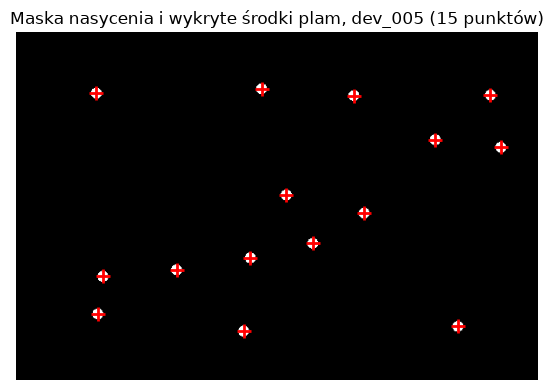

In [6]:
example_path = IMAGES_DIR / "dev" / "dev_005.png"
mask = detect.saturation_mask(example_path)
centroids = detect.blob_centroids(mask)

fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
ax.imshow(mask, cmap="gray")
xs, ys = zip(*centroids)
ax.scatter(xs, ys, marker="+", color="red", s=100, linewidths=2)
ax.set_title(f"Maska nasycenia i wykryte środki plam, dev_005 ({len(centroids)} punktów)")
ax.axis("off")
fig.tight_layout()

## 4. Wyniki

Podsumowanie metryk na dev i test, policzone w `evaluate.py` i tu tylko wczytane:

In [7]:
summary_df = pd.read_csv(SUMMARY_PATH)
summary_df.round(4)

,split,n_images,n_true,n_pred,n_matched,precision,recall,f1,mae_x,mae_y
0,dev,10,88,88,88,1.0,1.0000,1.0000,0.0009,0.0015
1,test,20,194,192,192,1.0,0.9897,0.9948,0.0010,0.0016


MAE w tabeli wyżej jest znormalizowane rozpiętością osi, więc trudno sobie wyobrazić,
ile to w praktyce. Przeliczam je na piksele: biorę średnią rozpiętość obszaru wykresu
w pikselach z `calibration.csv` i mnożę przez MAE ze `summary.csv` dla zbioru test.

In [8]:
calibration_df["px_width"] = calibration_df["px_right"] - calibration_df["px_left"]
calibration_df["px_height"] = calibration_df["px_bottom"] - calibration_df["px_top"]
mean_px_width = calibration_df["px_width"].mean()
mean_px_height = calibration_df["px_height"].mean()

test_summary = summary_df[summary_df["split"] == "test"].iloc[0]
mae_x_px = test_summary["mae_x"] * mean_px_width
mae_y_px = test_summary["mae_y"] * mean_px_height
print(f"MAE w pikselach (test): x = {mae_x_px:.2f} px, y = {mae_y_px:.2f} px")

MAE w pikselach (test): x = 0.52 px, y = 0.54 px


Średnio mylę się o mniej niż jeden piksel. Dev wyszedł bezbłędnie (1.0 na każdej metryce), test prawie identycznie.
Jedyne braki to dokładnie te przypadki stykających się lub nakładających się punktów
pokazane niżej.

Kilka udanych przykładów i obie porażki ze zbioru testowego. Wybieram je tą samą
regułą co `evaluate.py`: porażka to brak dopasowania albo nadmiarowa detekcja.

In [9]:
metrics_df = pd.read_csv(METRICS_PATH)
predictions_df = pd.read_csv(PREDICTIONS_PATH)

failures, successes = evaluate.select_examples(metrics_df)
print("Porażki:", failures)
print("Przykłady sukcesu:", successes)

Porażki: ['test_112', 'test_118']
Przykłady sukcesu: ['test_100', 'test_101', 'test_102']


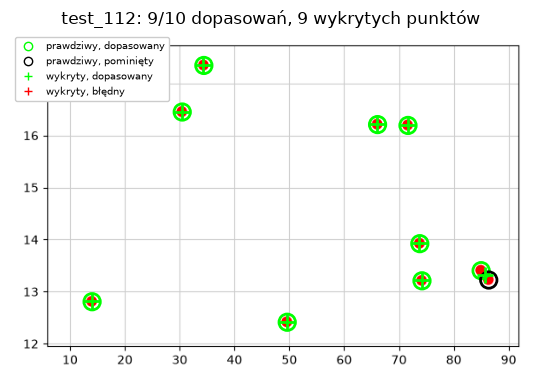

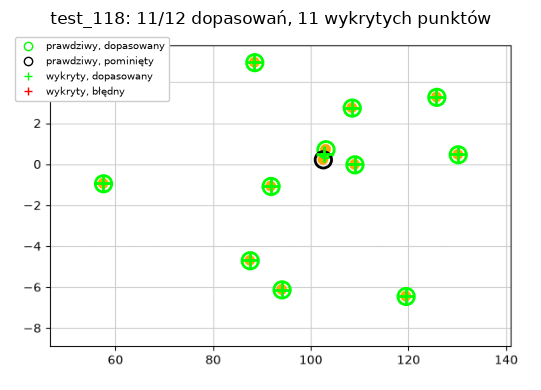

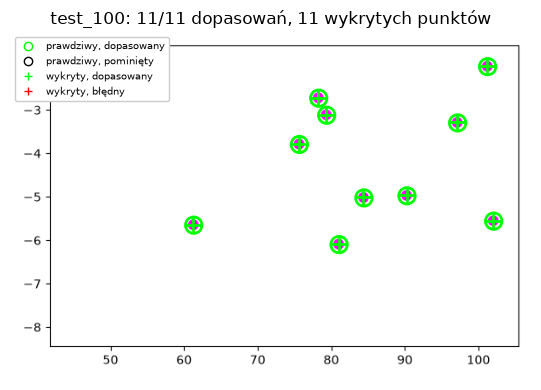

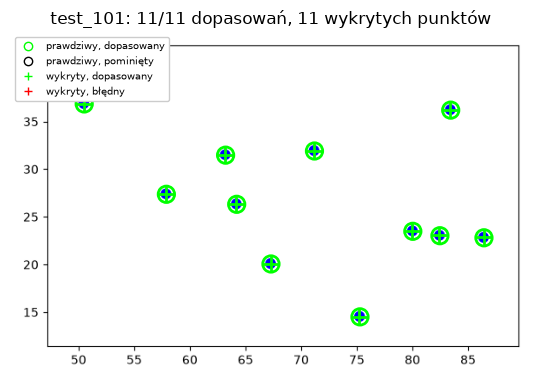

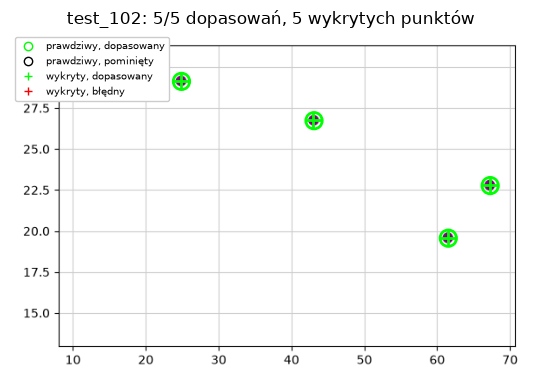

In [10]:
for image_id in failures + successes:
    calibration = calibration_indexed.loc[image_id]
    true_points = evaluate.points_for_image(ground_truth_df, image_id, "x_true", "y_true")
    pred_points = evaluate.points_for_image(predictions_df, image_id, "x_pred", "y_pred")
    _, matches = evaluate.evaluate_image(true_points, pred_points, calibration)
    evaluate.plot_detection(image_id, calibration, true_points, pred_points, matches)

## 5. Wnioski

- Wyniki są bardzo wysokie (F1 niemal 1.0 na dev i test), ale głównie dlatego, że dane
  spełniają założenia metody: markery są zawsze w pełni nasycone, a tło, siatka i osie
  praktycznie nie mają koloru. Rozdzielenie ich jednym progiem nasycenia jest tu łatwe.
  Na realnym wykresie (skan, zrzut ekranu, inny styl kolorystyczny) byłoby trudniej.
- Wyniki na moich danych syntetycznych nie dowodzą skuteczności na wykresach
  z publikacji. Naturalnym kolejnym krokiem byłoby sprawdzenie metody na realnych
  obrazach, np. z proponowanego PlotQA.
- Cztery elementy pod kątem problemów:
  - Markery: to jedyne realne źródło błędu w tych danych. Stykające się lub
    nakładające się punkty zlewają się w jedną plamę i liczą się jako jeden wykryty
    punkt (oba przypadki porażek powyżej).
  - Siatka: nie przeszkadza, bo rysuję ją pod markerami (`set_axisbelow`) i jest
    szara, więc nie przechodzi przez próg nasycenia.
  - Rozdzielczość: nie testowałem innych rozdzielczości ani kompresji, więc nie wiem,
    jak metoda by się zachowała.
  - Przeliczanie współrzędnych: działa poprawnie, błąd wynosi mniej niż piksel (sekcja
    Wyniki wyżej). Kalibrację biorę prosto z generatora, więc przeliczanie jest dokładne. Ten mały błąd bierze się z tego, że środek wykrytej plamy nie zawsze wypada idealnie w środku markera.  Przy
    ręcznej kalibracji na prawdziwym wykresie doszedłby do tego błąd kalibracji
    i całość wypadłaby gorzej.
- Gdzie metoda przestaje działać: wykresy z linią łączącą punkty w kolorze markera
  (linia skleja punkty w jedną długą plamę, więc takich wykresów nie obsługuję, mimo
  że treść zadania je dopuszcza) oraz wykresy z szarymi albo czarnymi markerami
  (nie przejdą przez próg nasycenia, bo mają nasycenie bliskie tła).
- Co zmieniłbym: przetestowałbym metodę na PlotQA zamiast tylko na własnych danych
  syntetycznych, i spróbowałbym rozdzielać zlepione plamy po rozmiarze. Plama mniej
  więcej dwa razy większa niż typowy marker to prawdopodobnie dwa punkty, nie jeden.